# Comparing Linear Regression, Lasso and Ridge

This notebook experiments with linear regression and L1/L2 regularisation using a generated dataset. It separates features and target, visualises a feature relationship, trains a baseline linear regression model, and explores regularised models.

**Learning focus:** understand how Lasso and Ridge add penalties to help control model complexity.


In [10]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [5]:
df = pd.read_csv("dataset.csv")
df.head(3)

,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,...,f142,f143,f144,f145,f146,f147,f148,f149,f150,target
0,-0.924357,-0.326536,-1.875007,-1.780626,-0.630143,0.788204,2.792209,-0.772192,-0.450994,0.400000,...,0.968645,-0.702053,-0.327662,-0.392108,-1.463515,0.296120,0.261055,0.005113,-0.234587,10.681366
1,0.001795,-1.285599,-0.726774,0.385711,0.891863,0.599451,-0.140553,-0.761760,0.117707,0.333231,...,0.856399,0.214094,-1.245739,0.173181,0.385317,-0.883857,0.153725,0.058209,-1.142970,-60.163343
2,0.956702,2.319330,-0.705012,0.081829,0.330880,0.838491,2.493000,1.227669,-0.785989,-0.920674,...,-0.493001,-0.589365,0.849602,0.357015,-0.692910,0.899600,0.307300,0.812862,0.629629,131.226545


In [6]:
X = df.drop(['target'],axis = 1)
y = df.target
X.head(3)

,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,...,f141,f142,f143,f144,f145,f146,f147,f148,f149,f150
0,-0.924357,-0.326536,-1.875007,-1.780626,-0.630143,0.788204,2.792209,-0.772192,-0.450994,0.400000,...,0.097078,0.968645,-0.702053,-0.327662,-0.392108,-1.463515,0.296120,0.261055,0.005113,-0.234587
1,0.001795,-1.285599,-0.726774,0.385711,0.891863,0.599451,-0.140553,-0.761760,0.117707,0.333231,...,-0.446515,0.856399,0.214094,-1.245739,0.173181,0.385317,-0.883857,0.153725,0.058209,-1.142970
2,0.956702,2.319330,-0.705012,0.081829,0.330880,0.838491,2.493000,1.227669,-0.785989,-0.920674,...,-0.208122,-0.493001,-0.589365,0.849602,0.357015,-0.692910,0.899600,0.307300,0.812862,0.629629


In [17]:
X.columns

Index(['f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10',
       ...
       'f141', 'f142', 'f143', 'f144', 'f145', 'f146', 'f147', 'f148', 'f149',
       'f150'],
      dtype='object', length=150)

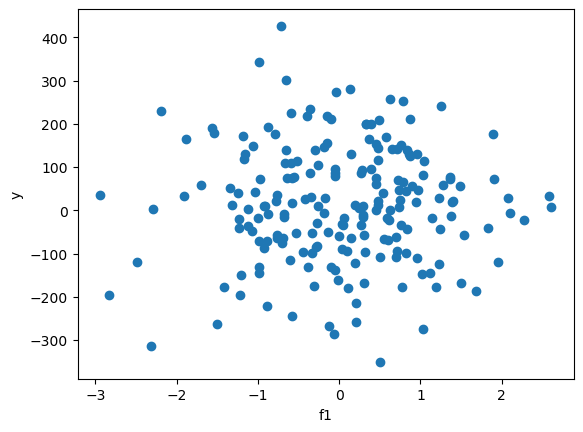

In [20]:
plt.scatter(X['f1'], y)
plt.xlabel('f1')
plt.ylabel('y')
plt.show()


In [7]:
y[:5]

0     10.681366
1    -60.163343
2    131.226545
3   -131.889020
4   -138.566956
Name: target, dtype: float64

In [11]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size= 0.25,random_state=42)
lm = LinearRegression()
lm.fit(X_train,y_train)
lm.score(X_test,y_test)

0.7410183335246805

In [24]:
lasso_model = Lasso(alpha = 1.0)
lasso_model.fit(X_train,y_train)
lasso_model.score(X_test,y_test)
len(lasso_model.coef_),lasso_model.intercept_

(150, np.float64(0.40750894954109107))

In [15]:
ridge_model = Ridge(alpha = 1.0)
ridge_model.fit(X_train,y_train)
ridge_model.score(X_test,y_test)

0.9462671341742044